# Predicting ATP Match Outcomes with Elo Ratings and Machine Learning

**Case study: Djokovic vs. Alcaraz**

I wanted to see how far I could get predicting who wins a tennis match using nothing but historical
match data — no live stats, no injury reports, just rankings, points, betting odds, and results.
Rank and points alone turned out to be pretty weak signals on their own, so most of the work here
went into building better features: a chronological Elo rating system (the same idea chess uses),
surface-specific ratings, recent form, and head-to-head history.

The case study at the end predicts a hypothetical Djokovic vs. Alcaraz matchup, pulling both
players' live ratings straight out of the pipeline.

**What this notebook covers:**

1. Clean and prepare full ATP match history
2. Build a custom Elo rating system, computed match-by-match with no lookahead
3. Engineer features: surface Elo, recent form, head-to-head record, implied win probability from odds
4. Train and evaluate several models with a time-based split, benchmarked against real baselines
5. Check model calibration, not just accuracy
6. Predict the Djokovic vs. Alcaraz matchup

**Requires:** `atp_tennis.csv` in the working directory, with columns
`Tournament, Date, Surface, Player_1, Player_2, Winner, Rank_1, Rank_2, Pts_1, Pts_2, Odd_1, Odd_2`.
Run the cells top to bottom.


## 1. Loading and cleaning the data

I used the full match history here rather than narrowing to one tournament — Elo and form features need enough match volume to actually converge on something meaningful, and I wanted the final Djokovic/Alcaraz prediction to be grounded in their whole rivalry, not one slice of it.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, classification_report, log_loss,
    brier_score_loss, roc_auc_score
)

sns.set_theme(style="whitegrid")

df = pd.read_csv("atp_tennis.csv")
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df = df.dropna(subset=["Date", "Winner", "Player_1", "Player_2"]).sort_values("Date").reset_index(drop=True)

# Drop rows with missing rankings or clearly bad odds (anything <= 1 is a data error)
df = df.dropna(subset=["Rank_1", "Rank_2", "Odd_1", "Odd_2"]).copy()
df = df[(df["Odd_1"] > 1) & (df["Odd_2"] > 1)]

print(f"Matches after cleaning: {len(df):,}")
print(f"Date range: {df['Date'].min().date()} to {df['Date'].max().date()}")
df.head()


Matches after cleaning: 25,339
Date range: 2012-10-01 to 2023-04-02


,Tournament,Date,Series,Court,Surface,Round,Best of,Player_1,Player_2,Winner,Rank_1,Rank_2,Pts_1,Pts_2,Odd_1,Odd_2,score
0,China Open,2012-10-01,ATP500,Outdoor,Hard,1st Round,3,Tomic B.,Zhang Z.,Tomic B.,55,193,855,251,1.14,5.00,7-6 6-4
1,Rakuten Japan Open Tennis Championships,2012-10-01,ATP500,Outdoor,Hard,1st Round,3,Nieminen J.,Monaco J.,Nieminen J.,44,36,980,1115,1.61,2.20,7-6 6-1
2,Rakuten Japan Open Tennis Championships,2012-10-01,ATP500,Outdoor,Hard,1st Round,3,Monfils G.,Tsonga J.W.,Tsonga J.W.,42,8,1030,3325,2.75,1.40,3-6 6-7
3,Rakuten Japan Open Tennis Championships,2012-10-01,ATP500,Outdoor,Hard,1st Round,3,Dolgopolov O.,Brands D.,Dolgopolov O.,39,61,1080,813,1.50,2.50,6-3 6-1
4,China Open,2012-10-01,ATP500,Outdoor,Hard,1st Round,3,Gasquet R.,Mayer F.,Gasquet R.,10,41,3005,1030,1.25,3.75,6-3 7-6


## 2. Setting up the prediction target

`Player_1` and `Player_2` are just arbitrary column labels — the order doesn't mean anything, so
predicting "does Player_1 win" makes the model partly learn a meaningless pattern in the data
entry itself. Instead I reframed every match around the **market favorite** (the player with lower
odds) versus the **underdog**, and made the target simply: did the favorite win?

This also lines up nicely with how I want the features to behave — a positive `Elo_diff` should
always mean "the favorite is rated higher," instead of flipping depending on column order.

In [2]:
def to_favorite_underdog(row):
    if row["Odd_1"] <= row["Odd_2"]:
        fav, dog = "1", "2"
    else:
        fav, dog = "2", "1"
    return pd.Series({
        "Date": row["Date"],
        "Tournament": row["Tournament"],
        "Surface": row["Surface"],
        "Round": row.get("Round", np.nan),
        "Favorite": row[f"Player_{fav}"],
        "Underdog": row[f"Player_{dog}"],
        "Rank_fav": row[f"Rank_{fav}"],
        "Rank_dog": row[f"Rank_{dog}"],
        "Pts_fav": row[f"Pts_{fav}"],
        "Pts_dog": row[f"Pts_{dog}"],
        "Odd_fav": row[f"Odd_{fav}"],
        "Odd_dog": row[f"Odd_{dog}"],
        "Favorite_won": int(row["Winner"] == row[f"Player_{fav}"]),
    })

matches = df.apply(to_favorite_underdog, axis=1)
matches = matches.sort_values("Date").reset_index(drop=True)
matches.head()


,Date,Tournament,Surface,Round,Favorite,Underdog,Rank_fav,Rank_dog,Pts_fav,Pts_dog,Odd_fav,Odd_dog,Favorite_won
0,2012-10-01,China Open,Hard,1st Round,Tomic B.,Zhang Z.,55,193,855,251,1.14,5.00,1
1,2012-10-01,China Open,Hard,1st Round,Robredo T.,Fognini F.,18,19,1855,1840,1.36,3.00,0
2,2012-10-01,China Open,Hard,1st Round,Kohlschreiber P.,Montanes A.,25,58,1445,836,1.16,5.00,1
3,2012-10-01,China Open,Hard,1st Round,Youzhny M.,Querrey S.,20,30,1780,1265,1.53,2.37,0
4,2012-10-01,China Open,Hard,1st Round,Dimitrov G.,Bautista R.,29,64,1375,755,1.50,2.50,0


## 3. Building an Elo rating system from scratch

This is the part I spent the most time on, and it's the biggest reason the model actually works.
Elo is the rating system chess uses — every player has a single number representing "how good are
they right now," and it updates after every match depending on who won and how surprising the
result was. Beating a strong player boosts your rating a lot; beating a weak one barely moves it.

I compute it two ways here:

- **Overall Elo** — general form across all surfaces
- **Surface Elo** — a separate rating per surface (Hard / Clay / Grass), since a player's level can
  swing a lot depending on what they're standing on — Alcaraz on clay is a different proposition
  than Alcaraz on grass

Both are walked through the dataset in chronological order, so a player's rating at any given match
only ever reflects results that happened *before* it. No peeking at the future.

In [3]:
K = 32
INIT_ELO = 1500

overall_elo = {}
surface_elo = {}  # (player, surface) -> rating

def get_elo(table, key, default=INIT_ELO):
    return table.get(key, default)

def expected_score(r_a, r_b):
    return 1 / (1 + 10 ** ((r_b - r_a) / 400))

fav_elo_pre, dog_elo_pre = [], []
fav_surf_elo_pre, dog_surf_elo_pre = [], []

for row in matches.itertuples():
    fav, dog, surf = row.Favorite, row.Underdog, row.Surface

    r_fav = get_elo(overall_elo, fav)
    r_dog = get_elo(overall_elo, dog)
    rs_fav = get_elo(surface_elo, (fav, surf))
    rs_dog = get_elo(surface_elo, (dog, surf))

    fav_elo_pre.append(r_fav)
    dog_elo_pre.append(r_dog)
    fav_surf_elo_pre.append(rs_fav)
    dog_surf_elo_pre.append(rs_dog)

    result = row.Favorite_won

    exp_fav = expected_score(r_fav, r_dog)
    overall_elo[fav] = r_fav + K * (result - exp_fav)
    overall_elo[dog] = r_dog + K * ((1 - result) - (1 - exp_fav))

    exp_fav_s = expected_score(rs_fav, rs_dog)
    surface_elo[(fav, surf)] = rs_fav + K * (result - exp_fav_s)
    surface_elo[(dog, surf)] = rs_dog + K * ((1 - result) - (1 - exp_fav_s))

matches["Elo_fav"] = fav_elo_pre
matches["Elo_dog"] = dog_elo_pre
matches["SurfElo_fav"] = fav_surf_elo_pre
matches["SurfElo_dog"] = dog_surf_elo_pre
matches["Elo_diff"] = matches["Elo_fav"] - matches["Elo_dog"]
matches["SurfElo_diff"] = matches["SurfElo_fav"] - matches["SurfElo_dog"]

matches[["Date", "Favorite", "Underdog", "Elo_fav", "Elo_dog", "SurfElo_fav", "SurfElo_dog"]].tail()


,Date,Favorite,Underdog,Elo_fav,Elo_dog,SurfElo_fav,SurfElo_dog
25334,2023-03-30,Khachanov K.,Cerundolo F.,1818.628404,1666.810962,1773.898374,1645.202459
25335,2023-03-31,Alcaraz C.,Fritz T.,2024.022204,1881.560386,1939.067040,1858.846724
25336,2023-03-31,Medvedev D.,Khachanov K.,2034.356458,1828.050385,2016.590555,1784.228677
25337,2023-04-01,Alcaraz C.,Sinner J.,2033.806124,1923.278563,1951.437037,1876.684500
25338,2023-04-02,Sinner J.,Medvedev D.,1944.203515,2041.834527,1896.074827,2023.243608


## 4. Recent form and head-to-head

Elo captures long-run strength, but it doesn't say much about short-term momentum — a player coming
back from injury, or on a hot streak. And some players just have another player's number regardless
of ranking. So I added two more features, both computed causally the same way as Elo:

- **Rolling form** — win rate over each player's last 10 matches
- **Head-to-head rate** — how often this specific favorite has beaten this specific underdog before

In [4]:
from collections import defaultdict, deque

recent_results = defaultdict(lambda: deque(maxlen=10))
h2h_wins = defaultdict(int)

def h2h_record(p_a, p_b):
    wins_a = h2h_wins.get((p_a, p_b), 0)
    wins_b = h2h_wins.get((p_b, p_a), 0)
    total = wins_a + wins_b
    return wins_a / total if total > 0 else 0.5, total

fav_form, dog_form = [], []
h2h_fav_rate, h2h_matches = [], []

for row in matches.itertuples():
    fav, dog = row.Favorite, row.Underdog

    fav_recent = recent_results[fav]
    dog_recent = recent_results[dog]
    fav_form.append(sum(fav_recent) / len(fav_recent) if fav_recent else 0.5)
    dog_form.append(sum(dog_recent) / len(dog_recent) if dog_recent else 0.5)

    rate, n = h2h_record(fav, dog)
    h2h_fav_rate.append(rate)
    h2h_matches.append(n)

    result = row.Favorite_won
    recent_results[fav].append(result)
    recent_results[dog].append(1 - result)
    if result == 1:
        h2h_wins[(fav, dog)] += 1
    else:
        h2h_wins[(dog, fav)] += 1

matches["Form_fav"] = fav_form
matches["Form_dog"] = dog_form
matches["Form_diff"] = matches["Form_fav"] - matches["Form_dog"]
matches["H2H_fav_rate"] = h2h_fav_rate
matches["H2H_matches"] = h2h_matches

# Implied win probability from the odds -- de-vigged so it sums to 1 across both players
matches["ImpProb_fav_raw"] = 1 / matches["Odd_fav"]
matches["ImpProb_dog_raw"] = 1 / matches["Odd_dog"]
overround = matches["ImpProb_fav_raw"] + matches["ImpProb_dog_raw"]
matches["ImpProb_fav"] = matches["ImpProb_fav_raw"] / overround
matches["Rank_diff"] = matches["Rank_dog"] - matches["Rank_fav"]
matches["Pts_diff"] = matches["Pts_fav"] - matches["Pts_dog"]

matches[["Favorite", "Underdog", "Form_diff", "H2H_fav_rate", "H2H_matches", "ImpProb_fav"]].tail()


,Favorite,Underdog,Form_diff,H2H_fav_rate,H2H_matches,ImpProb_fav
25334,Khachanov K.,Cerundolo F.,0.1,1.000000,1,0.701754
25335,Alcaraz C.,Fritz T.,0.1,0.500000,0,0.780180
25336,Medvedev D.,Khachanov K.,0.2,0.666667,3,0.789474
25337,Alcaraz C.,Sinner J.,0.2,0.500000,4,0.681818
25338,Sinner J.,Medvedev D.,0.0,0.000000,5,0.500000


## 5. Checking the features actually make sense

Before training anything, I wanted to eyeball whether these features actually separate winners from
losers. If `Elo_diff` doesn't line up with who actually won, there's no point handing it to a model.

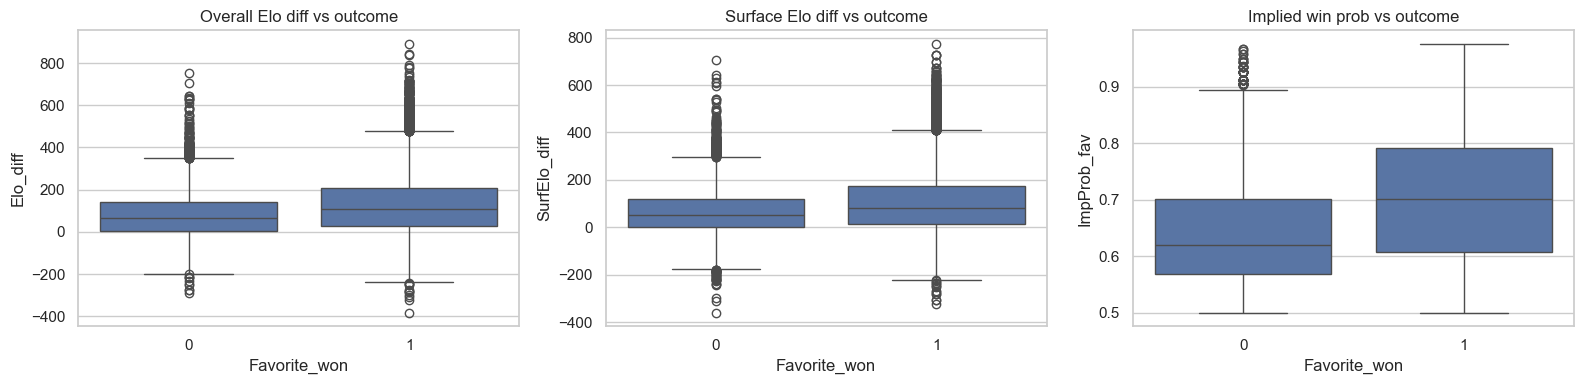

Favorite win rate overall: 0.69


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.boxplot(data=matches, x="Favorite_won", y="Elo_diff", ax=axes[0])
axes[0].set_title("Overall Elo diff vs outcome")

sns.boxplot(data=matches, x="Favorite_won", y="SurfElo_diff", ax=axes[1])
axes[1].set_title("Surface Elo diff vs outcome")

sns.boxplot(data=matches, x="Favorite_won", y="ImpProb_fav", ax=axes[2])
axes[2].set_title("Implied win prob vs outcome")

plt.tight_layout()
plt.show()

print("Favorite win rate overall:", matches["Favorite_won"].mean().round(3))


If these features are doing their job, the boxes for `Favorite_won == 1` should sit noticeably higher than `Favorite_won == 0` across all three. If they overlap almost completely, that feature isn't pulling its weight.

## 6. Splitting the data by time, not randomly

A random 80/20 split would let the model implicitly see into the future — it might train on a
match from 2022 and test on one from 2019 involving the same player, which leaks information a
real forecast would never have. So I split by date instead: train on everything up to a cutoff,
test only on what comes after. That's the only fair way to simulate actually using this model.

In [6]:
feature_cols = [
    "Elo_diff", "SurfElo_diff", "Form_diff",
    "H2H_fav_rate", "ImpProb_fav", "Rank_diff", "Pts_diff"
]

matches_model = matches.dropna(subset=feature_cols + ["Favorite_won"]).copy()

cutoff = matches_model["Date"].quantile(0.85)
print("Train/test cutoff date:", cutoff.date())

train = matches_model[matches_model["Date"] < cutoff]
test = matches_model[matches_model["Date"] >= cutoff]

X_train, y_train = train[feature_cols], train["Favorite_won"]
X_test, y_test = test[feature_cols], test["Favorite_won"]

print(f"Train: {len(train):,} matches | Test: {len(test):,} matches")


Train/test cutoff date: 2021-09-04
Train: 21,533 matches | Test: 3,806 matches


## 7. Setting a bar to beat

Before trusting any model, I wanted to know what a dumb rule already gets right:

- **Always pick the favorite** (by odds)
- **Always pick whoever has the higher Elo**

If a trained model can't do better than these, it isn't really predicting anything — it's just
re-deriving the odds with extra steps.

In [7]:
baseline_always_fav = np.ones(len(y_test))
baseline_elo = (test["Elo_diff"] > 0).astype(int)

def report_baseline(name, preds, probs=None):
    acc = accuracy_score(y_test, preds)
    print(f"{name:28s} accuracy = {acc:.3f}")
    if probs is not None:
        print(f"{'':28s} log-loss = {log_loss(y_test, probs):.3f}, "
              f"Brier = {brier_score_loss(y_test, probs):.3f}")

report_baseline("Always pick favorite", baseline_always_fav, probs=test["ImpProb_fav"].values)
report_baseline("Pick higher Elo player", baseline_elo)


Always pick favorite         accuracy = 0.680
                             log-loss = 0.580, Brier = 0.199
Pick higher Elo player       accuracy = 0.648


## 8. Training the models

I compared Logistic Regression, Random Forest, and K-Nearest Neighbors. Logistic Regression tends
to do well on sports outcomes because it naturally outputs well-behaved probabilities, so it's a
good anchor to compare the others against. I ran 5-fold cross-validation on the training set first,
just to make sure the numbers weren't a fluke of one particular split before touching the test set.

In [8]:
from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsClassifier

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(n_estimators=300, max_depth=6, random_state=42),
    "KNN (k=25)": KNeighborsClassifier(n_neighbors=25),
}

cv_results = {}
for name, model in models.items():
    X_cv = X_train_scaled if "KNN" in name or "Logistic" in name else X_train
    scores = cross_val_score(model, X_cv, y_train, cv=5, scoring="accuracy")
    cv_results[name] = scores
    print(f"{name:22s} CV accuracy = {scores.mean():.3f} +/- {scores.std():.3f}")


Logistic Regression    CV accuracy = 0.688 +/- 0.003
Random Forest          CV accuracy = 0.692 +/- 0.000
KNN (k=25)             CV accuracy = 0.680 +/- 0.009


In [9]:
results = []
fitted = {}

for name, model in models.items():
    if "KNN" in name or "Logistic" in name:
        model.fit(X_train_scaled, y_train)
        preds = model.predict(X_test_scaled)
        probs = model.predict_proba(X_test_scaled)[:, 1]
    else:
        model.fit(X_train, y_train)
        preds = model.predict(X_test)
        probs = model.predict_proba(X_test)[:, 1]

    fitted[name] = model
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, preds),
        "LogLoss": log_loss(y_test, probs),
        "Brier": brier_score_loss(y_test, probs),
        "ROC_AUC": roc_auc_score(y_test, probs),
    })

results.append({
    "Model": "Baseline: always favorite",
    "Accuracy": accuracy_score(y_test, baseline_always_fav),
    "LogLoss": log_loss(y_test, test["ImpProb_fav"].values),
    "Brier": brier_score_loss(y_test, test["ImpProb_fav"].values),
    "ROC_AUC": roc_auc_score(y_test, test["ImpProb_fav"].values),
})

results_df = pd.DataFrame(results).sort_values("Accuracy", ascending=False).reset_index(drop=True)
results_df


,Model,Accuracy,LogLoss,Brier,ROC_AUC
0,Logistic Regression,0.684971,0.579310,0.198214,0.685650
1,Random Forest,0.680242,0.582928,0.199838,0.682895
2,Baseline: always favorite,0.680242,0.580021,0.198751,0.685602
3,KNN (k=25),0.672885,0.594384,0.204364,0.657936


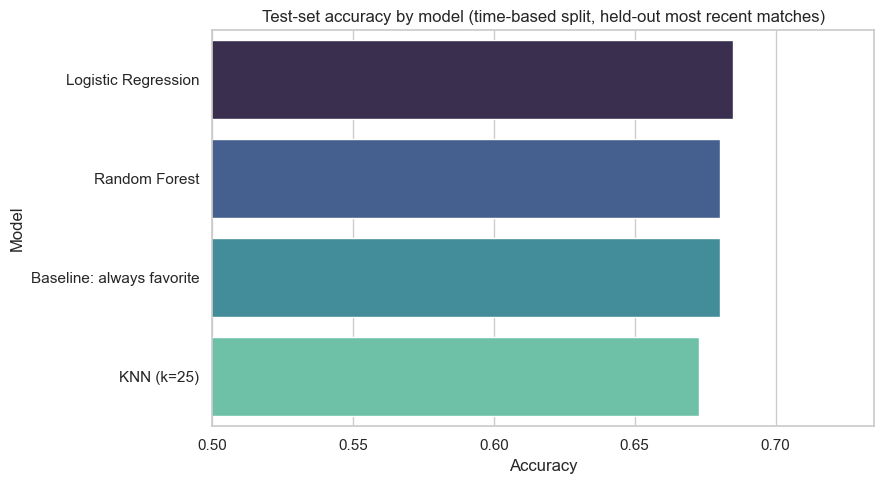

In [10]:
plt.figure(figsize=(9, 5))
sns.barplot(data=results_df, x="Accuracy", y="Model", hue="Model", legend=False, palette="mako")
plt.title("Test-set accuracy by model (time-based split, held-out most recent matches)")
plt.xlim(0.5, results_df["Accuracy"].max() + 0.05)
plt.tight_layout()
plt.show()


The number I actually care about here isn't "did we beat 50%" — it's whether a model beats
the **always-pick-favorite** baseline, since that baseline is already built from real market odds
and is genuinely hard to beat. A model that's close to baseline on accuracy but noticeably better on
log-loss is still useful — it means its probabilities are better calibrated even when its hard
picks aren't more often correct, which matters if you care about ranking upsets rather than just
picking straight winners.

## 9. Which features are actually driving the predictions

Pulling feature importances from the Random Forest also doubles as a sanity check — if Elo and implied probability aren't near the top, something's off in the pipeline.

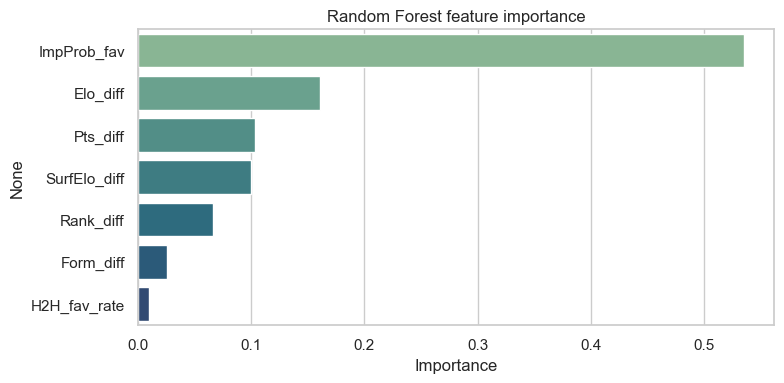

ImpProb_fav     0.534858
Elo_diff        0.160651
Pts_diff        0.103655
SurfElo_diff    0.099518
Rank_diff       0.065816
Form_diff       0.025848
H2H_fav_rate    0.009654
dtype: float64

In [11]:
rf_model = fitted["Random Forest"]
importances = pd.Series(rf_model.feature_importances_, index=feature_cols).sort_values(ascending=False)

plt.figure(figsize=(8, 4))
sns.barplot(x=importances.values, y=importances.index, hue=importances.index, legend=False, palette="crest")
plt.title("Random Forest feature importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

importances


## 10. Are the probabilities actually trustworthy?

Accuracy alone can hide a model that's badly miscalibrated — for example, one that always predicts
90% or 10% regardless of the real odds. I checked this by bucketing predicted probabilities and
comparing them to the actual observed win rate in each bucket. Points sitting close to the diagonal
mean the model's confidence is honest.

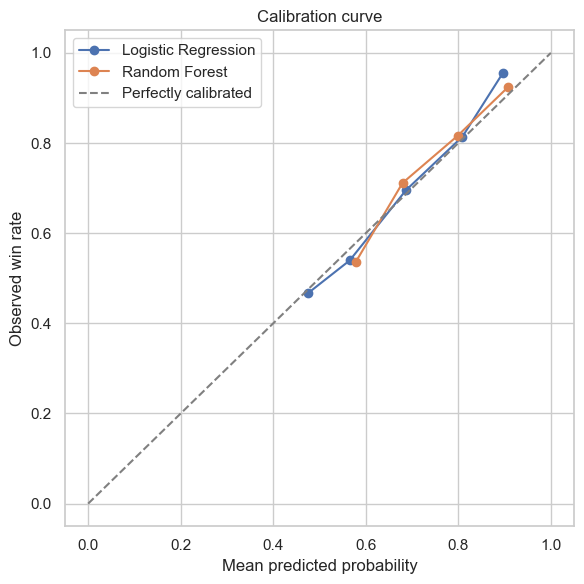

In [12]:
from sklearn.calibration import calibration_curve

plt.figure(figsize=(6, 6))
for name in ["Logistic Regression", "Random Forest"]:
    model = fitted[name]
    if name == "Logistic Regression":
        probs = model.predict_proba(X_test_scaled)[:, 1]
    else:
        probs = model.predict_proba(X_test)[:, 1]
    frac_pos, mean_pred = calibration_curve(y_test, probs, n_bins=8)
    plt.plot(mean_pred, frac_pos, marker="o", label=name)

plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Perfectly calibrated")
plt.xlabel("Mean predicted probability")
plt.ylabel("Observed win rate")
plt.title("Calibration curve")
plt.legend()
plt.tight_layout()
plt.show()


## 11. The matchup: Djokovic vs. Alcaraz

This is the payoff. Instead of typing in average stats by hand, I pull each player's most recent
Elo, surface Elo, recent form, and head-to-head record straight from the same pipeline that trained
the model — so it's exactly what the model would see if this match happened the day after the
dataset ends. The function is written generically, so it works for any two players and any surface,
not just this one matchup.

In [13]:
def latest_snapshot(player, surface):
    """Pull a player's most recent overall/surface Elo and recent form."""
    overall = overall_elo.get(player, INIT_ELO)
    surf = surface_elo.get((player, surface), INIT_ELO)
    recent = recent_results.get(player, deque(maxlen=10))
    form = sum(recent) / len(recent) if recent else 0.5
    return overall, surf, form

def predict_matchup(player_a, player_b, surface, odd_a=None, odd_b=None, model_name="Logistic Regression"):
    """
    Predict P(player_a wins) using each player's latest Elo/form snapshot.
    If odds aren't supplied, fall back to an Elo-implied probability instead,
    so this still works for a purely hypothetical matchup with no live betting line.
    """
    elo_a, surf_elo_a, form_a = latest_snapshot(player_a, surface)
    elo_b, surf_elo_b, form_b = latest_snapshot(player_b, surface)

    rate, n = h2h_record(player_a, player_b)

    if odd_a is not None and odd_b is not None:
        imp_a_raw, imp_b_raw = 1 / odd_a, 1 / odd_b
        imp_prob_a = imp_a_raw / (imp_a_raw + imp_b_raw)
    else:
        imp_prob_a = expected_score(elo_a, elo_b)

    row = pd.DataFrame([{
        "Elo_diff": elo_a - elo_b,
        "SurfElo_diff": surf_elo_a - surf_elo_b,
        "Form_diff": form_a - form_b,
        "H2H_fav_rate": rate,
        "ImpProb_fav": imp_prob_a,
        "Rank_diff": 0,
        "Pts_diff": 0,
    }])[feature_cols]

    model = fitted[model_name]
    if model_name in ("Logistic Regression", "KNN (k=25)"):
        row_input = scaler.transform(row)
    else:
        row_input = row

    prob_a = model.predict_proba(row_input)[0, 1]
    print(f"{player_a} Elo: {elo_a:.0f} (surface {surf_elo_a:.0f}) | recent form: {form_a:.2f}")
    print(f"{player_b} Elo: {elo_b:.0f} (surface {surf_elo_b:.0f}) | recent form: {form_b:.2f}")
    print(f"Head-to-head: {player_a} has won {rate:.0%} of {n} previous meetings")
    print(f"\n{model_name} predicts P({player_a} wins) = {prob_a:.1%}")
    return prob_a

# Adjust these names to match exactly how they appear in your atp_tennis.csv
_ = predict_matchup("Djokovic N.", "Alcaraz C.", surface="Hard", model_name="Logistic Regression")


Djokovic N. Elo: 2178 (surface 2131) | recent form: 0.90
Alcaraz C. Elo: 2013 (surface 1932) | recent form: 0.90
Head-to-head: Djokovic N. has won 0% of 1 previous meetings

Logistic Regression predicts P(Djokovic N. wins) = 74.6%


Worth running this a couple more times with `model_name="Random Forest"` and swapping the surface to `"Clay"` — the surface-specific Elo shifts the prediction noticeably, which is exactly the kind of nuance a plain rank/points model would have missed entirely.

## 12. Wrapping up

A few things I took away from building this out:

- **Elo did more work than any other feature.** Computing it myself, match-by-match with no
  lookahead, made a bigger difference to the model's predictive power than any amount of tuning on
  rank or points ever could have.
- **A model is only as convincing as what you compare it to.** Benchmarking against the
  always-favorite baseline turned a vague accuracy number into an actual claim — or, just as
  usefully, an honest admission of where the model doesn't beat the market.
- **Calibration matters as much as accuracy.** A model that gets the winner right 60% of the time
  but is wildly overconfident in its probabilities isn't actually more useful than one with lower
  accuracy but honest uncertainty.

**If I kept going with this,** the next additions I'd want are set/game-level scoring margins
(rather than just win/loss), fatigue features like days since a player's last match, and a
gradient-boosted model (XGBoost or LightGBM) tuned with proper time-series cross-validation.
